In [58]:
%pip install statsmodels
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [59]:
# Load Dataset yang tersedia dan identifikasi tipe data setiap kolom (nominal, ordinal, interval, rasio) 
import pandas as pd

df = pd.read_csv('fdi_2020.csv')
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 173 entries, 0 to 172
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   country                 173 non-null    str    
 1   FDI_in_millions         173 non-null    float64
 2   interest                173 non-null    float64
 3   income_tax              173 non-null    float64
 4   corporate_tax           173 non-null    float64
 5   population_in_millions  173 non-null    float64
 6   GDP_in_billions         173 non-null    float64
 7   unemployment            173 non-null    float64
 8   inflation               173 non-null    float64
 9   gov_expense_per_GDP     173 non-null    float64
 10  oecd_status             173 non-null    str    
dtypes: float64(9), str(2)
memory usage: 15.0 KB


In [60]:
df.head(10)

,country,FDI_in_millions,interest,income_tax,corporate_tax,population_in_millions,GDP_in_billions,unemployment,inflation,gov_expense_per_GDP,oecd_status
0,Afghanistan,38.5,5.7,20.0,20.0,38.0,76.6,11.1,2.3,28.2,nonOECD
1,Albania,1281.3,3.6,23.0,15.0,2.9,39.8,12.3,1.4,29.1,nonOECD
2,Algeria,1381.9,13.8,35.0,26.0,43.1,668.8,11.7,2.0,38.5,nonOECD
3,Angola,-4098.5,7.4,17.0,30.0,31.8,200.8,6.9,17.1,20.9,nonOECD
4,Argentina,6244.4,13.7,35.0,30.0,44.9,911.6,9.8,53.5,39.6,nonOECD
5,Armenia,254.5,5.6,23.0,18.0,3.0,33.4,17.0,1.4,25.0,nonOECD
6,Australia,36156.2,2.6,45.0,30.0,25.4,1362.1,5.3,1.6,37.4,Member
7,Austria,4642.6,3.0,55.0,25.0,8.9,476.8,4.7,1.5,48.6,Member
8,Azerbaijan,1503.9,8.5,25.0,20.0,10.0,187.3,5.5,2.6,34.1,nonOECD
9,Bahrain,941.8,5.7,0.0,0.0,1.6,76.9,0.7,1.0,33.1,nonOECD


In [61]:
# buat tabel ringkasan statistik untuk seluruh variable (mean, std deviasi, nilai min, nilai max, quartile, dll) 

df.describe(include='all')

,country,FDI_in_millions,interest,income_tax,corporate_tax,population_in_millions,GDP_in_billions,unemployment,inflation,gov_expense_per_GDP,oecd_status
count,173,173.000000,173.000000,173.000000,173.000000,173.000000,173.000000,173.000000,173.000000,173.000000,173
unique,173,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nonOECD
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,135
mean,NaN,8512.537572,7.493064,28.541618,23.222543,43.346821,811.564740,7.063006,120.398844,30.683237,NaN
std,NaN,25880.456982,4.508527,13.387368,8.679534,153.142712,2845.338107,5.527028,1513.155568,11.158098,NaN
min,NaN,-21740.000000,0.000000,0.000000,0.000000,0.100000,0.400000,0.100000,-16.400000,11.500000,NaN
25%,NaN,229.900000,3.000000,20.000000,19.000000,2.800000,31.200000,3.400000,0.900000,21.600000,NaN
50%,NaN,998.200000,6.500000,30.000000,25.000000,9.700000,96.300000,5.300000,2.300000,30.800000,NaN
75%,NaN,4631.200000,10.400000,37.000000,30.000000,31.800000,476.000000,9.500000,4.400000,37.500000,NaN


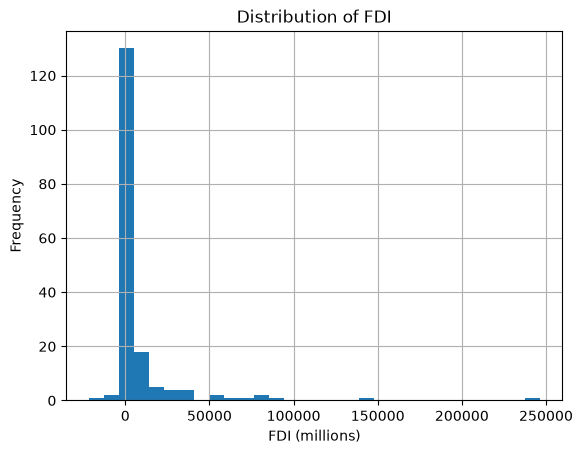

In [62]:
# buat histogram variable target (FDI) untuk melihat distribusinya 
import matplotlib.pyplot as plt

df['FDI_in_millions'].hist(bins=30)
plt.xlabel('FDI (millions)')
plt.ylabel('Frequency')
plt.title('Distribution of FDI')
plt.show()

In [63]:
# identifikasi apakah terdapat outliers untuk variable target (FDI) menggunakan rumus interquartile yaitu (Q1-1.5*IQR) dan (Q3+1.5*IQR). Jika ada, sebutkan unit observasinya (nama negara) 

Q1 = df['FDI_in_millions'].quantile(0.25)
Q3 = df['FDI_in_millions'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['FDI_in_millions'] < lower_bound) | (df['FDI_in_millions'] > upper_bound)]
print("Outliers:")
print(outliers[['country', 'FDI_in_millions']])

Outliers:
                  country  FDI_in_millions
6               Australia          36156.2
20                 Brazil          71989.3
29                 Canada          50331.9
32                  Chile          11437.4
33                  China         141225.0
34               Colombia          14493.1
39                 Cyprus          24248.0
55                 France          33964.7
58                Germany          36358.6
69                  India          50553.0
70              Indonesia          23429.0
72                Ireland          78234.1
73                 Israel          18224.2
74                  Italy          26569.5
76                  Japan          14552.4
89             Luxembourg         -11420.8
98                 Mexico          32921.2
107           Netherlands          84215.6
121                Poland          13220.5
126                Russia          31735.1
136             Singapore          92080.5
142                 Spain          12405.5
1

In [64]:
# berikan interpretasi terhadap analisis statistika deskriptif yang sudah dilakukan 
df.describe()


,FDI_in_millions,interest,income_tax,corporate_tax,population_in_millions,GDP_in_billions,unemployment,inflation,gov_expense_per_GDP
count,173.000000,173.000000,173.000000,173.000000,173.000000,173.000000,173.000000,173.000000,173.000000
mean,8512.537572,7.493064,28.541618,23.222543,43.346821,811.564740,7.063006,120.398844,30.683237
std,25880.456982,4.508527,13.387368,8.679534,153.142712,2845.338107,5.527028,1513.155568,11.158098
min,-21740.000000,0.000000,0.000000,0.000000,0.100000,0.400000,0.100000,-16.400000,11.500000
25%,229.900000,3.000000,20.000000,19.000000,2.800000,31.200000,3.400000,0.900000,21.600000
50%,998.200000,6.500000,30.000000,25.000000,9.700000,96.300000,5.300000,2.300000,30.800000
75%,4631.200000,10.400000,37.000000,30.000000,31.800000,476.000000,9.500000,4.400000,37.500000
max,246215.000000,22.100000,60.000000,50.000000,1397.700000,27307.000000,28.200000,19906.000000,86.900000


Dari tabel statistik, jumlah datanya ada **173 negara**.

- Rata-rata FDI sekitar **8.512,54 juta**, sedangkan nilai tengahnya **998,2 juta**. Jadi, ada beberapa negara dengan FDI yang besar. FDI yang bernilai negatif juga ada di data.
- Rata-rata populasi sekitar **43,35 juta**, tetapi nilai tengahnya **9,7 juta**. Ini menunjukkan ukuran populasi antarnegara cukup berbeda.
- Rata-rata GDP sekitar **811,56 miliar**, sementara nilai tengahnya **96,3 miliar**. Beberapa negara memiliki GDP jauh lebih besar dari negara lainnya.
- Rata-rata pengangguran sekitar **7,06%** dan nilai tengahnya **5,3%**.
- Inflasi memiliki nilai tengah **2,3%**, tetapi rata-ratanya **120,40%**. Nilai maksimum **19.906** sangat besar, jadi data ini sebaiknya dicek lagi.
- Suku bunga, pajak penghasilan, pajak perusahaan, dan belanja pemerintah juga memiliki nilai yang berbeda-beda antarnegara.

Secara umum, beberapa nilai yang sangat besar membuat rata-rata lebih tinggi daripada nilai tengah. Jadi, nilai tengah juga perlu diperhatikan saat membaca data.

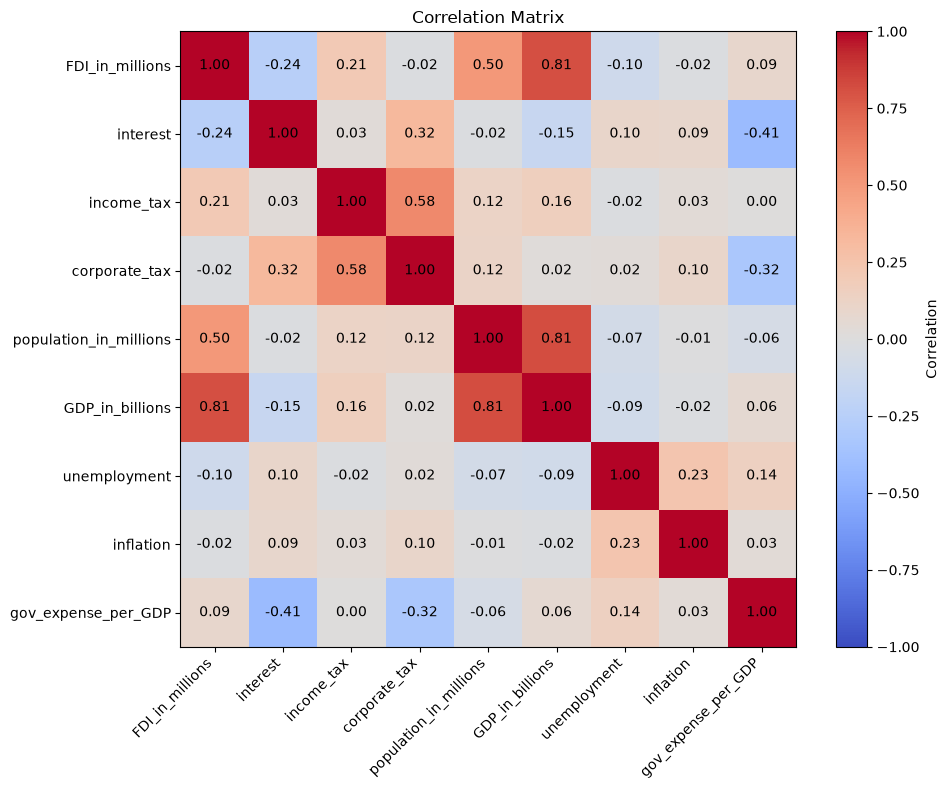

Variable independent with correlation > 50%:
GDP_in_billions           0.807389
population_in_millions    0.504468
Name: FDI_in_millions, dtype: float64


In [65]:
# buat heatmap analisis korelasi dan identifikasi variable independent yang memiliki nilai korelasi > 50% terhadap variable target 


numeric_df = df.select_dtypes(include='number')
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')

columns = correlation_matrix.columns
plt.xticks(range(len(columns)), columns, rotation=45, ha='right')
plt.yticks(range(len(columns)), columns)

for i in range(len(columns)):
	for j in range(len(columns)):
		plt.text(j, i, f'{correlation_matrix.iloc[i, j]:.2f}',
				 ha='center', va='center')

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

# identifikasi variable independent dengan korelasi > 50% terhadap variable target
target_correlations = correlation_matrix['FDI_in_millions'].drop('FDI_in_millions').abs().sort_values(ascending=False)
significant_vars = target_correlations[target_correlations > 0.5]
print("Variable independent with correlation > 50%:")
print(significant_vars)

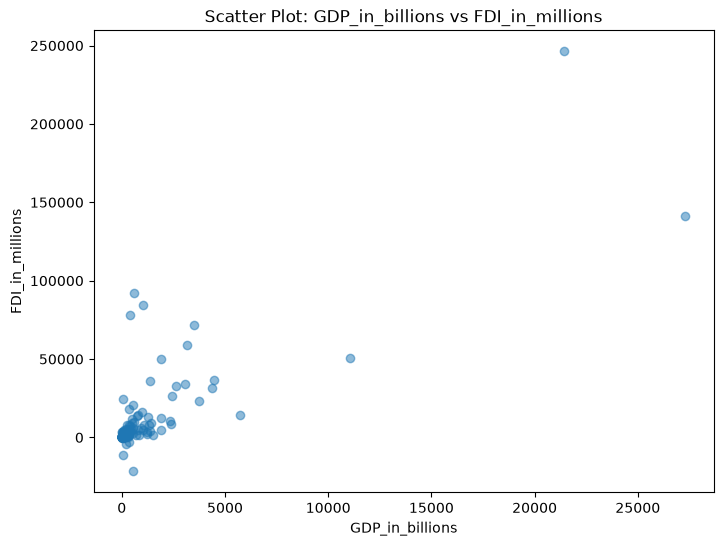

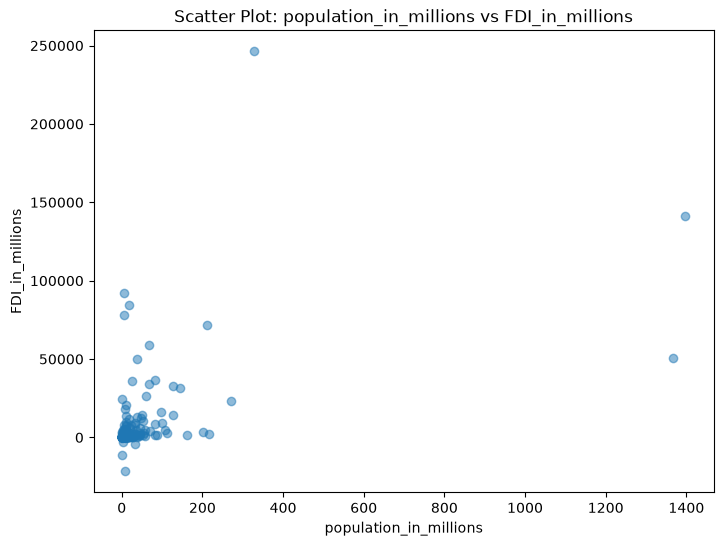

In [66]:
# buat scatterplot antara variable target (Y axis) dan setiap variable response (X axis) yang telah teridentifikasi pada pertanyaan 3a 
for var in significant_vars.index:
    plt.figure(figsize=(8, 6))
    plt.scatter(df[var], df['FDI_in_millions'], alpha=0.5)
    plt.xlabel(var)
    plt.ylabel('FDI_in_millions')
    plt.title(f'Scatter Plot: {var} vs FDI_in_millions')
    plt.show()

C:\Users\060111667\AppData\Local\Temp\ipykernel_25704\1603773500.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for var in df.select_dtypes(include='object').columns:


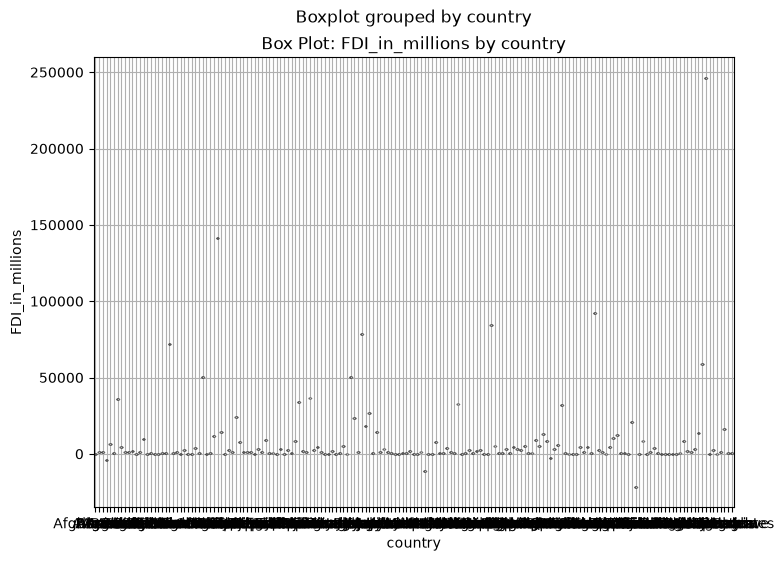

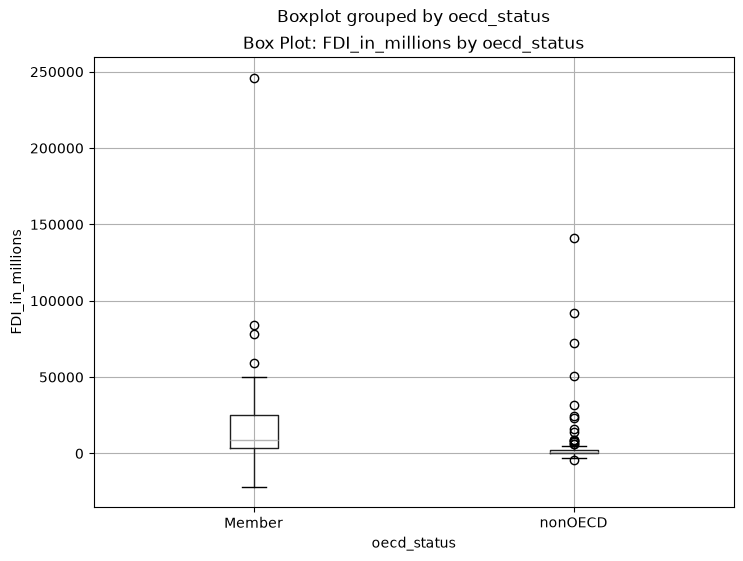

In [67]:
# buat boxplot variable target berdasarkan nilai variable kategorik, identifikasi apakah terdapat perbedaan nilai FDI diantara nilai variable kategorik 

for var in df.select_dtypes(include='object').columns:
    plt.figure(figsize=(8, 6))
    df.boxplot(column='FDI_in_millions', by=var, ax=plt.gca())
    plt.title(f'Box Plot: FDI_in_millions by {var}')
    plt.xlabel(var)
    plt.ylabel('FDI_in_millions')
    plt.show()

analisis regresi (meskipun terdapat outliers)

Dari hasil korelasi sebelumnya, saya memilih beberapa variabel untuk dicoba dalam model regresi. Ini adalah dugaan awal saya, belum tentu hasilnya terbukti.

- **Hipotesis 1:** GDP yang lebih besar diduga berhubungan dengan FDI yang lebih besar.
- **Hipotesis 2:** Populasi yang lebih besar diduga berhubungan dengan FDI.
- **Hipotesis 3:** Belanja pemerintah terhadap GDP mungkin juga berhubungan dengan FDI.

In [68]:
# Lakukan 3 jenis fitting regresi yaitu FDI vs variable numerik terpilih, FDI vs variable kategorik terpilih, dan FDI vs mixed variable terpilih. (Tips: Lakukan one hot encoding untuk variable kategorik) 

import statsmodels.api as sm

# Pastikan sudah melakukan dropping missing values atau imputasi jika perlu
df_clean = df.dropna()

# --- 1. FDI vs variable numerik terpilih ---
# Misal: GDP_billions, Population_millions, Gov_spending_percentage
numeric_features = ['GDP_in_billions', 'population_in_millions', 'gov_expense_per_GDP']
X_num = df_clean[numeric_features]
X_num = sm.add_constant(X_num) # Menambahkan intercept
y = df_clean['FDI_in_millions']

model_num = sm.OLS(y, X_num).fit()
print("Model Numerik:")
print(model_num.summary())

# --- 2. FDI vs variable kategorik terpilih ---
# Asumsi: Ada kolom kategorik, misal 'Region'
df_encoded = pd.get_dummies(df_clean, columns=['oecd_status'], drop_first=True, dtype=int)

# Memilih kolom hasil encoding untuk kategorik saja (sesuaikan dengan nama kolom yang ada)
categorical_features = [column for column in df_encoded.columns if column.startswith('oecd_status_')]
X_cat = sm.add_constant(df_encoded[categorical_features])

model_cat = sm.OLS(y, X_cat).fit()
print("\nModel Kategorik:")
print(model_cat.summary())

# --- 3. FDI vs mixed variable terpilih ---
# Menggabungkan fitur numerik dan kategorik (One-Hot Encoded)
X_mixed = df_encoded[numeric_features + categorical_features]
X_mixed = sm.add_constant(X_mixed)

model_mixed = sm.OLS(y, X_mixed).fit()
print("\nModel Mixed:")
print(model_mixed.summary())


Model Numerik:
                            OLS Regression Results                            
Dep. Variable:        FDI_in_millions   R-squared:                       0.720
Model:                            OLS   Adj. R-squared:                  0.715
Method:                 Least Squares   F-statistic:                     145.2
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           1.50e-46
Time:                        09:58:12   Log-Likelihood:                -1892.6
No. Observations:                 173   AIC:                             3793.
Df Residuals:                     169   BIC:                             3806.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const        

In [69]:
# Identifikasi satu model regresi terbaik berdasarkan nilai R-Square (adj) dan nilai p-value uji-t 

models = {
    "Numerik": model_num,
    "Kategorik": model_cat,
    "Mixed": model_mixed,
}

best_model_name, best_model = max(
    models.items(),
    key=lambda item: item[1].rsquared_adj
)

print(f"Model terbaik: {best_model_name}")
print(f"Adjusted R-squared: {best_model.rsquared_adj:.3f}")
print(best_model.pvalues)

Model terbaik: Mixed
Adjusted R-squared: 0.725
const                     6.683105e-03
GDP_in_billions           1.659735e-34
population_in_millions    3.543523e-08
gov_expense_per_GDP       2.143716e-01
oecd_status_nonOECD       1.037753e-02
dtype: float64


In [70]:
# Tulis model persamaan regresi terbaik (Y = b0 + biX1 + …) dan interpretasikan koefisiennya (nilai Beta1, Beta2, dst.) 

print("Model Persamaan Regresi Terbaik:")
print(best_model.params)


Model Persamaan Regresi Terbaik:
const                     12993.295784
GDP_in_billions              10.265099
population_in_millions      -69.895587
gov_expense_per_GDP        -129.366131
oecd_status_nonOECD       -7448.518307
dtype: float64


Hasil model menunjukkan model **Mixed** memiliki adjusted R-squared sekitar **0,725**. Artinya, model ini menjelaskan sekitar 72,5% perbedaan FDI pada data yang digunakan.

Persamaan modelnya kira-kira:

**FDI = 12.993,30 + 10,27(GDP) - 69,90(Populasi) - 129,37(Belanja pemerintah) - 7.448,52(Status nonOECD)**

Dengan variabel lain dianggap tetap:

- Jika GDP naik 1 miliar, prediksi FDI naik sekitar **10,27 juta**.
- Jika populasi naik 1 juta, prediksi FDI turun sekitar **69,90 juta** pada model ini.
- Koefisien belanja pemerintah bernilai negatif, tetapi hasilnya belum signifikan karena p-value-nya sekitar **0,214**.
- Negara dengan status nonOECD diperkirakan memiliki FDI sekitar **7.448,52 juta lebih rendah** daripada kategori Member.

Hasil ini menunjukkan hubungan dalam model, tetapi belum tentu membuktikan sebab-akibat. Nilai outlier juga perlu diperhatikan.

Ya, outlier bisa memengaruhi hasil regresi. Nilai FDI yang sangat jauh dari nilai negara lain bisa menarik garis regresi, sehingga hasil koefisiennya berubah.

Pada pemeriksaan IQR, ada beberapa nilai FDI yang terdeteksi sebagai outlier, termasuk nilai FDI yang sangat besar. Tapi nilai tersebut tidak boleh langsung dihapus karena bisa saja benar.

Cara yang bisa dilakukan adalah memeriksa datanya dulu, memperbaiki jika ada salah input, lalu membandingkan hasil regresi dengan dan tanpa nilai yang dicurigai. Bisa juga memakai metode regresi yang lebih tahan terhadap outlier.